# comparaison des methodes ADAPT : shift trend

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from adapt_utils import run_all_methods

/Users/arnaudgrassian/Downloads/stage_recherche/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## Execution (sans et avec standardisation)

In [2]:
shift_type = "trend"

results_raw = run_all_methods(shift_type, standardize=False)
results_std = run_all_methods(shift_type, standardize=True)

results_raw["standardise"] = False
results_std["standardise"] = True
results_df = pd.concat([results_raw, results_std], ignore_index=True)
results_df

,method,intensity,mse_source,mse_target,r2_source,r2_target,standardise
0,sans adaptation,0.25,0.033010,3.223669e-02,0.951031,9.509000e-01,False
1,sans adaptation,0.50,0.033010,3.267167e-02,0.951031,9.571636e-01,False
2,sans adaptation,1.00,0.033010,3.399680e-02,0.951031,9.676550e-01,False
3,CORAL,0.25,0.033010,1.010953e+01,0.951031,-1.439792e+01,False
4,CORAL,0.50,0.033010,2.462993e+01,0.951031,-3.129274e+01,False
5,CORAL,1.00,0.033010,7.288473e+01,0.951031,-6.834353e+01,False
6,SA,0.25,0.033010,3.384364e+00,0.951031,-4.154757e+00,False
7,SA,0.50,0.033010,8.194024e+00,0.951031,-9.743331e+00,False
8,SA,1.00,0.033010,2.412892e+01,0.951031,-2.195658e+01,False
9,TCA,0.25,19.939197,4.908079e+02,-28.578813,-7.465542e+02,False


## Comparaison (r2 cible)

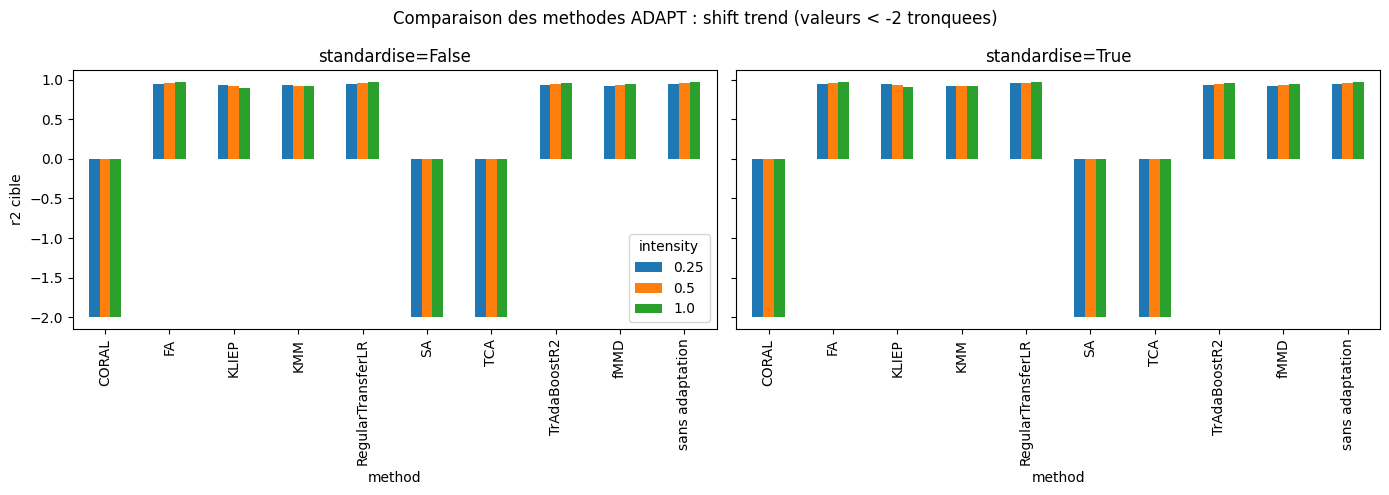

In [3]:
plot_floor = -2

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, standardise in zip(axes, [False, True]):
    subset = results_df[results_df["standardise"] == standardise]
    pivot = subset.pivot(index="method", columns="intensity", values="r2_target").clip(lower=plot_floor)
    pivot.plot(kind="bar", ax=ax, legend=(ax is axes[0]))
    ax.set_title(f"standardise={standardise}")
    ax.set_ylabel("r2 cible")

plt.suptitle(f"Comparaison des methodes ADAPT : shift {shift_type} (valeurs < {plot_floor} tronquees)")
plt.tight_layout()
plt.show()

## Source vs cible (sans standardisation)

In [4]:
subset = results_df[~results_df["standardise"]]
subset.pivot_table(index="method", columns="intensity", values=["r2_source", "r2_target"])

r2_source                              r2_target  \
intensity               0.25        0.50           1.00        0.25   
method                                                                
CORAL               0.951031    0.951031       0.951031  -14.397916   
FA                  0.951012    0.950995       0.950945    0.952579   
KLIEP               0.934585    0.926284       0.916650    0.930915   
KMM                 0.934682    0.933167       0.934261    0.927672   
RegularTransferLR   0.948152    0.948109       0.947831    0.952670   
SA                  0.951031    0.951031       0.951031   -4.154757   
TCA               -28.578813 -160.372205 -149967.001637 -746.554206   
TrAdaBoostR2        0.928572    0.928780       0.928723    0.931121   
fMMD                0.940308    0.940308       0.940308    0.924330   
sans adaptation     0.951031    0.951031       0.951031    0.950900   

                                              
intensity                 0.50          1.00  
method                                        
CORAL               -31.292736 -6.834353e+01  
FA                    0.959199  9.703989e-01  
KLIEP                 0.915520  8.979968e-01  
KMM                   0.923710  9.237755e-01  
RegularTransferLR     0.959275  9.704595e-01  
SA                   -9.743331 -2.195658e+01  
TCA               -4161.729224 -1.381665e+08  
TrAdaBoostR2          0.940636  9.569000e-01  
fMMD                  0.932581  9.460885e-01  
sans adaptation       0.957164  9.676550e-01

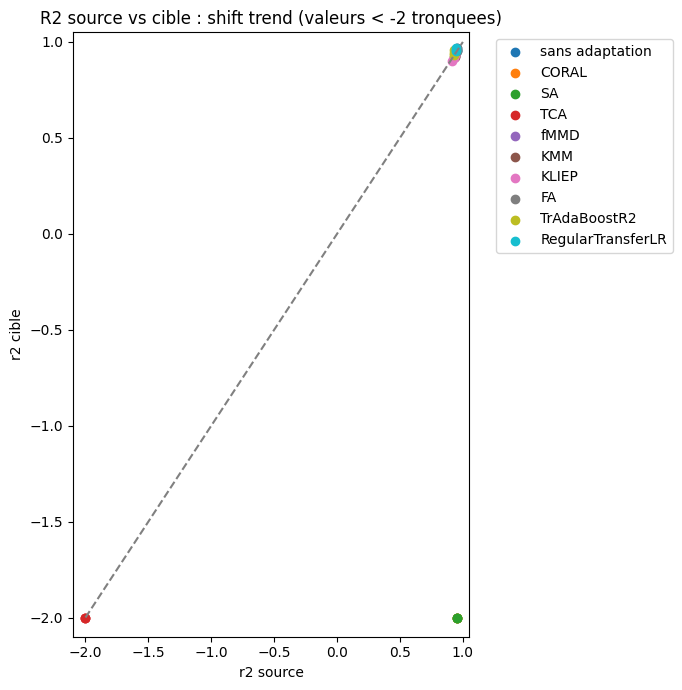

In [5]:
plot_floor = -2

fig, ax = plt.subplots(figsize=(7, 7))
for method in subset["method"].unique():
    method_data = subset[subset["method"] == method]
    x = method_data["r2_source"].clip(lower=plot_floor)
    y = method_data["r2_target"].clip(lower=plot_floor)
    ax.scatter(x, y, label=method)

ax.plot([plot_floor, 1], [plot_floor, 1], linestyle="--", color="gray")
ax.set_xlim(plot_floor - 0.1, 1.05)
ax.set_ylim(plot_floor - 0.1, 1.05)
ax.set_xlabel("r2 source")
ax.set_ylabel("r2 cible")
ax.set_title(f"R2 source vs cible : shift {shift_type} (valeurs < {plot_floor} tronquees)")
ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()